In [1]:
%pip install pandas numpy scikit-learn imbalanced-learn joblib matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
!pip install imbalanced-learn
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV
import joblib

#Load the Dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.head())

print("\n")

print(df.info())

print("\n")

print("Duplicates :", df.duplicated().sum())

print("\n")

print(df.describe())

print("\n")

#Convert them into NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print(df.info())

print("\n")

print(df.isnull().sum())

print("\n")

#Remove Missing Rows
df = df.dropna()
print("NULL values dropped successfully!")

print("\n")

print(df.isnull().sum())

print("\n")

print(df.shape)

print("\n")

#MAIN - Exploratory Data Analysis (EDA)
print(df["Churn"].value_counts(dropna=False))

print("\n")

print(df['Contract'].value_counts(dropna=False))

print("\n")

#Mapping 1 & 0 Label Encoding (Binary Encoding)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print(df['Churn'].value_counts(dropna=False))

print("\n")

#Separate Features and Target
x = df.drop('Churn', axis=1)
y = df['Churn']
x = x.drop('customerID', axis=1)

print(x.shape)
print(y.shape)

print("\n")

#Apply One-Hot Encoding
x = pd.get_dummies(x, drop_first=True)
print(x.head())

print("\n")

print("X Shape: ", x.shape)
print("Y Shape: ", y.shape)

print("\n")

#the train-test split step
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("Train and Test separeted Counts: ")
print(x_train.shape)
print(x_test.shape)

print("\n")

#Scaling
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Scaler Successful!")


print(y_train.value_counts(dropna=False))
print("\n")

#Model Training
#Baseline Logistic Regression
logis_model = LogisticRegression(solver='liblinear', max_iter=2000)
logis_model.fit(x_train, y_train)

print("Model Trained Successfully!")

print("\n")

#Predicting Baseline the model
y_pred = logis_model.predict(x_test)

print("Pred Value: ", y_pred)
print("Actual Value: ", "\n", y_test)

print("\n")

#Evaluate Baseline the model (accuracy_score, confusion_matrix, classification_report)
accuracy = accuracy_score(y_test, y_pred)
confu = confusion_matrix(y_test, y_pred)
print("Accuracy: ", accuracy)
print("Confusion Matrix: \n", confu)

print(classification_report(y_test, y_pred))

print("\n")

#Scaled Model Logistic Regression
logis_model_scaled = LogisticRegression(solver='liblinear', max_iter=2000)
logis_model_scaled.fit(x_train_scaled, y_train)

print("Scaled Model Trained Successfully!")

print("\n")

#Predicting Scaled the model
y_pred_scaled = logis_model_scaled.predict(x_test_scaled)

print("Pred Value: ", y_pred_scaled)
print("Actual Value: ", "\n", y_test)

print("\n")

#Evaluate Scaled the model (accuracy_score, confusion_matrix, classification_report)
print(classification_report(y_test, y_pred_scaled))

print("\n")

#Before jumping into the next step -  Check all (precision/ recall(VERY IMPORTANT for target)/ f1-score/ support) Estimated proper score should be above (0.75)

#Balanced Logistic Regression Model
balanced_model = LogisticRegression(solver='liblinear', max_iter=2000, class_weight='balanced')
balanced_model.fit(x_train_scaled, y_train)

print("Balanced Model Trained Successfully!")

print("\n")

#Predicting Balanced the model
y_pred_balanced = balanced_model.predict(x_test_scaled)

print("Pred Value: ", y_pred_balanced)
print("Actual Value: ", "\n", y_test)

print("\n")

#Evaluate Balanced the model (accuracy_score, confusion_matrix, classification_report)
print(classification_report(y_test, y_pred_balanced))

print("\n")

#Random Forest Model (Non Linear Model)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(x_train, y_train)

print("Random Forest Model Trained Successfully!")

print("\n")

#Predicting Random Forest the model
rf_model_pred = rf_model.predict(x_test)

print("Predicted Values :", rf_model_pred)
print("Actual Values :", "\n", y_test)

print("\n")

#Evaluate Random Forest the model (accuracy_score, confusion_matrix, classification_report)
print(classification_report(y_test, rf_model_pred))

print("\n")

#Feature Importance Analysis (Extract Feature Importance) (This is wear it shows your churn driver!) = For Random Forest Model (Non Linear Model)
importance_rf = rf_model.feature_importances_

feature_importance = pd.DataFrame({'Feature': x.columns, 'Importance': importance_rf})

feature_importance = feature_importance.sort_values(by='Importance', ascending=False)

print("Feature Importance")
print(feature_importance.head(10))

print("\n")

#SMOTE (Synthetic Minority Oversampling Technique)
smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train_scaled, y_train)

print("SMOTE Successful!")

print("\n")

print("SMOTE Count: ")
print(y_train_smote.value_counts(dropna=False))

print("\n")

#Smote Logistic Regression Model
smote_model = LogisticRegression(solver='liblinear', max_iter=2000)
smote_model.fit(x_train_smote, y_train_smote)

print("Smote Logistic Model Trained Successfully!")

print("\n")

#Predicting Smote Logistic Regression Model
y_pred_smote = smote_model.predict(x_test_scaled)

print("Predicted Value :", y_pred_smote)
print("Actual value :", "\n", y_test)

print("\n")

#Evaluate Smote Logistic Regression Model (accuracy_score, confusion_matrix, classification_report)
print(classification_report(y_test, y_pred_smote))

print("\n")

#Smote Random Forest the Model
smote_rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
smote_rf_model.fit(x_train_smote, y_train_smote)

print("Smote Random Forest Model Trained Successfully!")

print("\n")

#Predicting Smote Random Forest the Model
y_pred_smote_rf = smote_rf_model.predict(x_test_scaled)

print("Predicted Value :", y_pred_smote_rf)
print("Actual value :", "\n", y_test)

print("\n")

#Evaluate Random Forest the Model (accuracy_score, confusion_matrix, classification_report)
print(classification_report(y_test, y_pred_smote_rf))

print("\n")

#Feature Importance Analysis (Extract Feature Importance) (This is wear it shows your churn driver!) = For Smote Logistic Regression Model
importance_smote = np.abs(smote_model.coef_[0])

feature_importance_smote = pd.DataFrame({'Feature': x.columns, 'Importance': importance_smote})

feature_importance_smote = feature_importance_smote.sort_values(by='Importance', ascending=False)

print("Feature Importance")
print(feature_importance_smote.head(10))

print("\n")

#ROC Curve & AUC Score
y_prob_smote = smote_model.predict_proba(x_test_scaled)[:, 1]
print(y_prob_smote)

print("\n")

fpr, tpr, thresholds = roc_curve(y_test, y_prob_smote)
auc_score = roc_auc_score(y_test, y_prob_smote)

print("AUC Score", auc_score)

print("\n")

#Hyperparameter Tuning - Random Forest
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5],
    'class_weight': ['balanced']
}

grid_search = GridSearchCV(estimator=RandomForestClassifier(random_state=42), param_grid=param_grid, cv=3, scoring='recall', n_jobs=-1)
grid_search.fit(x_train, y_train)

print("Best Parameter: ", grid_search.best_params_)
print("Best Score: ", grid_search.best_score_)

print("\n")

#Tuned Random Forest + SMOTE - Final Optimized Model
final_rf_model = RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_split=5, class_weight='balanced', random_state=42)
final_rf_model.fit(x_train_smote, y_train_smote)

print("Final Random Forest Model Trained Successfully!")

print("\n")

#Predicting Final Smote Random Forest the Model
y_pred_final_rf = final_rf_model.predict(x_test_scaled)

print("Predicted Value :", y_pred_final_rf)
print("Actual Value :", "\n", y_test)

print("\n")

#Evaluate Final Smote Random Forest the Model (accuracy_score, confusion_matrix, classification_report)
print(classification_report(y_test, y_pred_final_rf))

print("\n")

#Feature Importance Analysis (Extract Feature Importance) (This is wear it shows your churn driver!) = For Final Tuned Smote Random Forest Model (Non Linear Model)
importance_tuned_rf = final_rf_model.feature_importances_

feature_importance_tuned_rf = pd.DataFrame({'Features': x.columns, 'Importance': importance_tuned_rf})

feature_importance_tuned_rf = feature_importance_tuned_rf.sort_values(by='Importance', ascending=False)

print("Feature Importance")
print(feature_importance_tuned_rf.head(10))

print("\n")

#Saving the (Model - Scaler - Features)
joblib.dump(final_rf_model, 'churn_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(x.columns.tolist(), 'feature_columns.pkl')

Defaulting to user installation because normal site-packages is not writeable
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...      

['feature_columns.pkl']

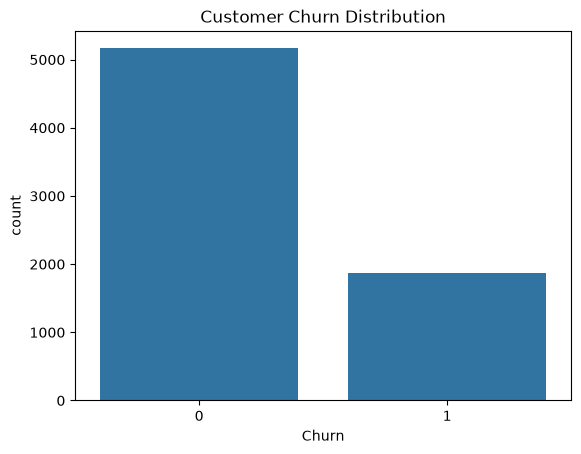

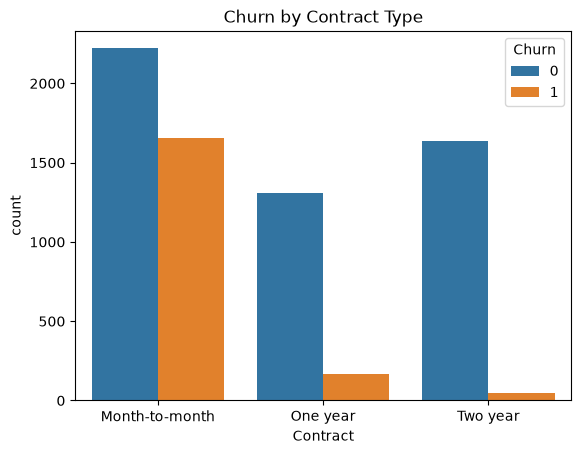

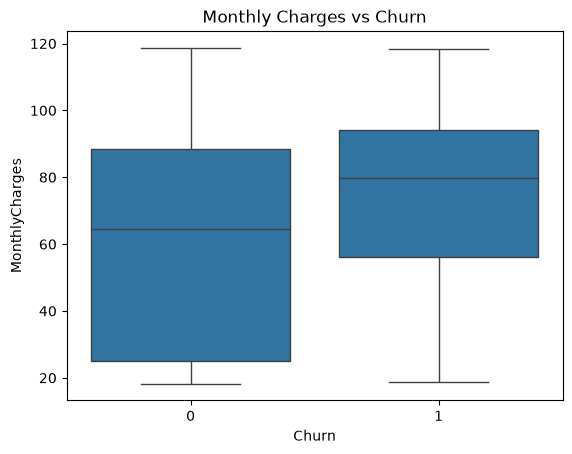

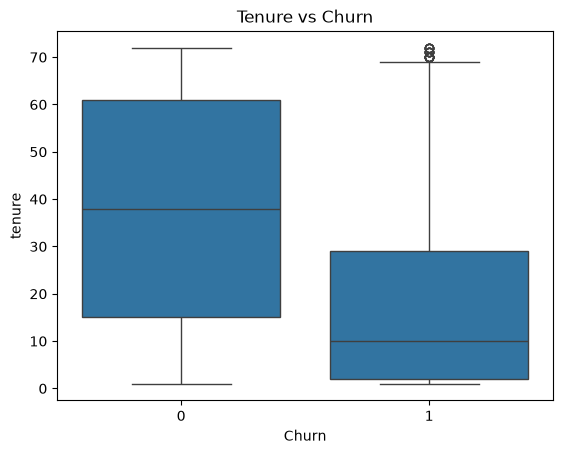

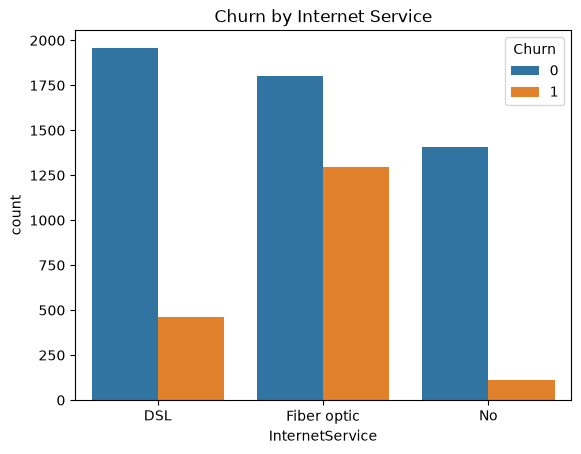

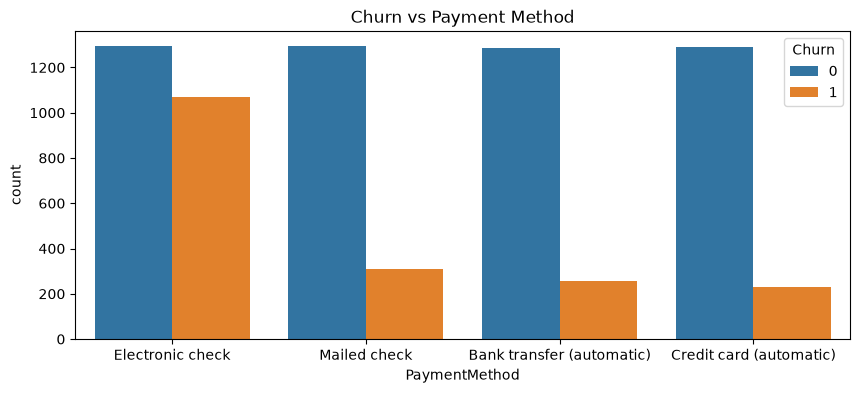

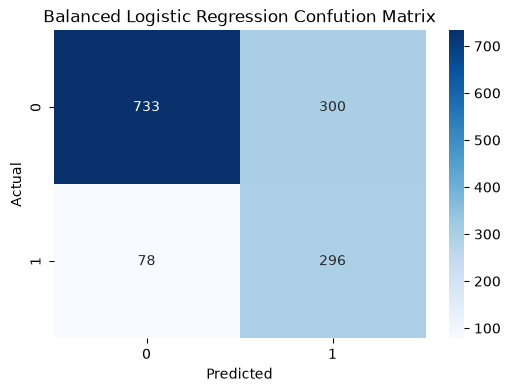

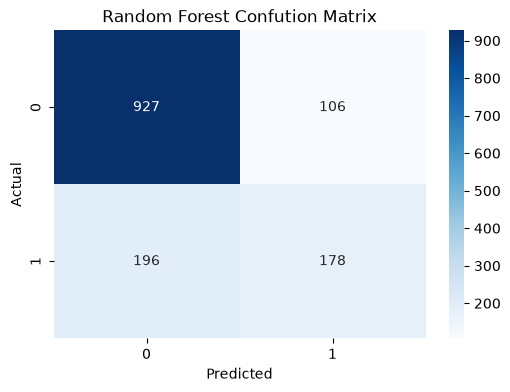

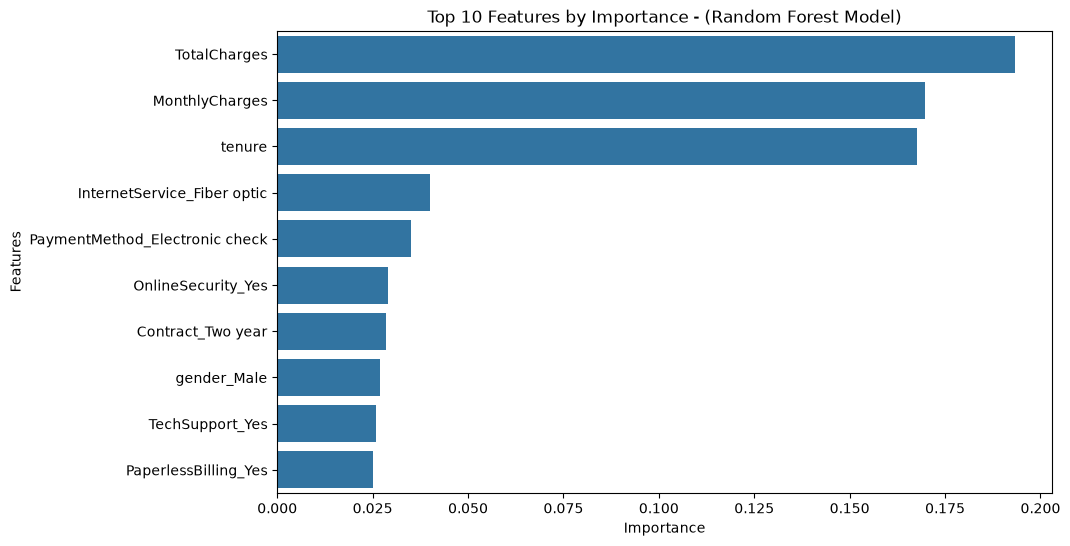

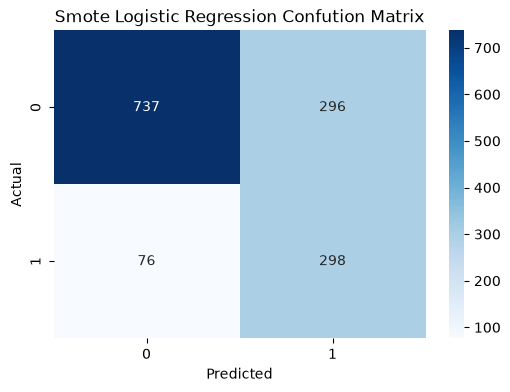

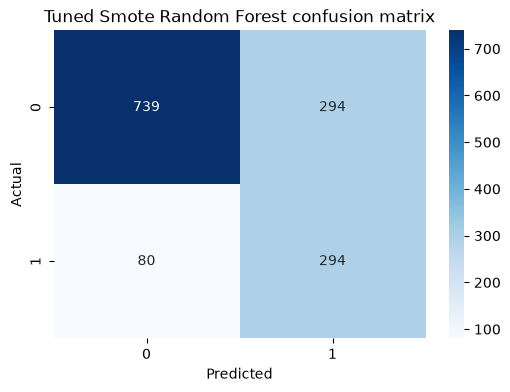

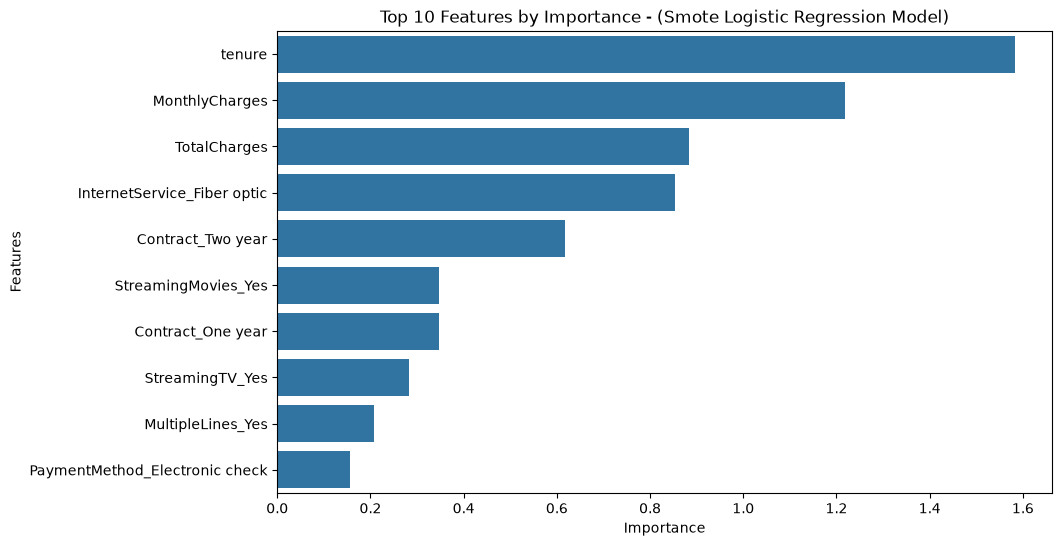

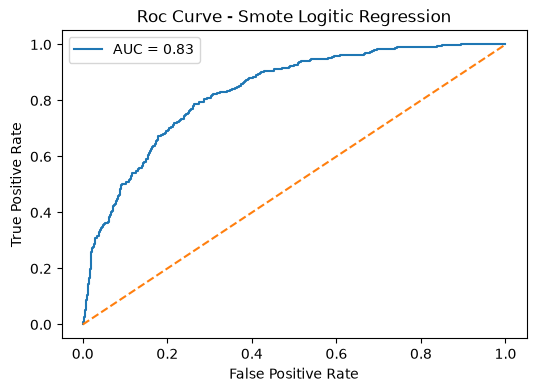

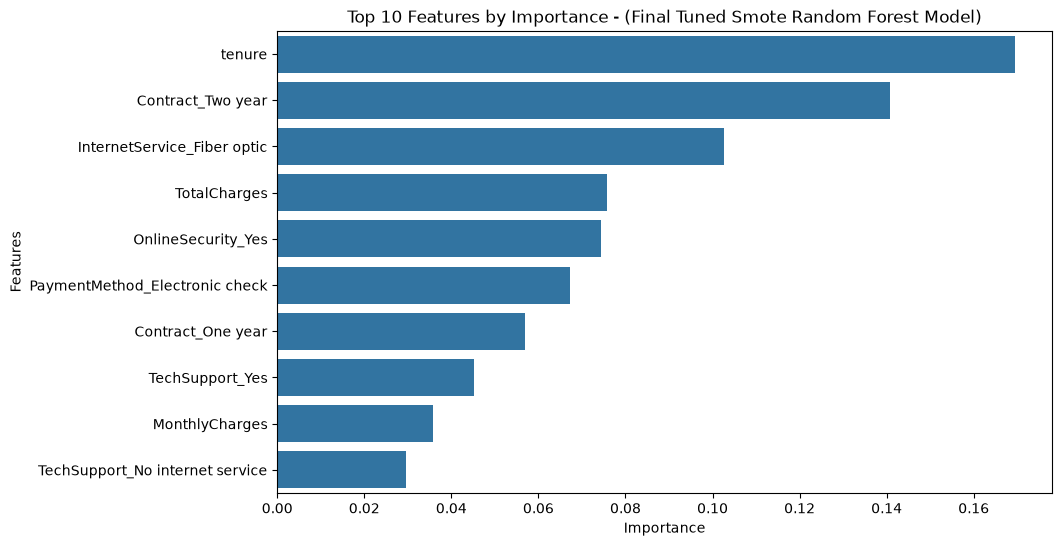

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='Churn', data=df)
plt.title("Customer Churn Distribution")
plt.show()

print("\n")

sns.countplot(x='Contract', hue='Churn', data=df)
plt.title("Churn by Contract Type")
plt.show()

print("\n")

sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title("Monthly Charges vs Churn")
plt.show()

print("\n")

sns.boxplot(x='Churn', y='tenure', data=df)
plt.title("Tenure vs Churn")
plt.show()

print("\n")

sns.countplot(x='InternetService', hue='Churn', data=df)
plt.title("Churn by Internet Service")
plt.show()

print("\n")

plt.figure(figsize=(10,4))

sns.countplot(x='PaymentMethod', hue='Churn', data=df)
plt.title("Churn vs Payment Method")
plt.show()

print("\n")

#These visualizations below are after testing (baseline logistic regression, scaled logistic regression, balanced logistic regression) these models = (balanced logistic regression)
cm = confusion_matrix(y_test, y_pred_balanced)

plt.figure(figsize=(6,4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Balanced Logistic Regression Confution Matrix")

plt.show()

print("\n")

#These visualizations below are after testing (Random Forest Model)
cm = confusion_matrix(y_test, rf_model_pred)

plt.figure(figsize=(6,4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confution Matrix")

plt.show()

print("\n")

#Visualization (Feature Importance Analysis) (Reason For Churn) - (Random Forest Model)
plt.figure(figsize=(10,6))

sns.barplot(x='Importance', y='Feature', data=feature_importance.head(10))

plt.title("Top 10 Features by Importance - (Random Forest Model)")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()

print("\n")

#This visualizations below are after testing (Smote Logistic Regression Model)
cm = confusion_matrix(y_test, y_pred_smote)

plt.figure(figsize=(6,4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Smote Logistic Regression Confution Matrix")

plt.show()

print("\n")

#This visualizations below are after testing (Smote Logistic Regression Model)
cm = confusion_matrix(y_test, y_pred_final_rf)

plt.figure(figsize=(6,4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Tuned Smote Random Forest confusion matrix")

plt.show()

print("\n")

#Visualization (Feature Importance Analysis) (Reason For Churn) - (Smote Logistic Regression Model)
plt.figure(figsize=(10,6))

sns.barplot(x='Importance', y='Feature', data=feature_importance_smote.head(10))

plt.title("Top 10 Features by Importance - (Smote Logistic Regression Model)")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()

print("\n")

#Plot ROC Curve
plt.figure(figsize=(6,4))

plt.plot(fpr, tpr, label=f"AUC = {auc_score:.2f}")

plt.plot([0,1], [0,1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Roc Curve - Smote Logitic Regression")

plt.legend()
plt.show()

print("\n")

#Visualization (Feature Importance Analysis) (Reason For Churn) - (Final Tuned Smote Random Forest Model)
plt.figure(figsize=(10,6))

sns.barplot(x='Importance', y='Features', data=feature_importance_tuned_rf.head(10))

plt.title("Top 10 Features by Importance - (Final Tuned Smote Random Forest Model)")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()